# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: **Nazakat Ali**  
Student ID: **023-22-0146**  
Section: **Buffer Batch**  
GitHub: **https://github.com/Nizakatkhannk**  
Kaggle: **https://www.kaggle.com/nizakatkhannk**  
Dataset: Stroke Prediction Dataset (Kaggle)  
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

> Run with `Runtime → Restart and run all`. Everything is seeded (`SEED = 42`). Sentences with **bold numbers** are generated by code from the current run, so they always match the tables above them.

## Part 0 — Setup and the Data

In [ ]:
import os, glob, subprocess, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
try:
    import imblearn
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'imbalanced-learn'], check=True); import imblearn
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
sns.set_style('whitegrid'); SEED = 42; pd.set_option('display.width', 220)
def say(t): display(Markdown(t))

In [ ]:
CSV = 'healthcare-dataset-stroke-data.csv'
hits = glob.glob(f'**/{CSV}', recursive=True)
if hits: CSV = hits[0]
else:
    try:
        try: import kagglehub
        except ImportError:
            subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'kagglehub'], check=True); import kagglehub
        CSV = os.path.join(kagglehub.dataset_download('fedesoriano/stroke-prediction-dataset'), CSV)
    except Exception as e:
        print('Auto-download failed:', e, '\nPlease upload the CSV manually.')
        from google.colab import files; CSV = list(files.upload().keys())[0]

raw = pd.read_csv(CSV, na_values=['NA', 'N/A', ''])
print('Shape:', raw.shape)
miss = raw.isna().sum(); print('\nColumns with missing values:\n', miss[miss > 0].to_string())
print('\nGender counts:\n', raw['gender'].value_counts().to_string())
vc = raw['stroke'].value_counts(); print('\nStroke counts:')
print(pd.DataFrame({'count': vc, 'percent': (100 * vc / len(raw)).round(2)}))

Shape: (5110, 12)

Columns with missing values:
 bmi    201

Gender counts:
 gender
Female    2994
Male      2115
Other        1

Stroke counts:
        count  percent
stroke                
0        4861    95.13
1         249     4.87


In [ ]:
# --- cleaning: drop id, drop gender categories that are too small, then split BEFORE imputing/encoding/scaling ---
raw = raw.drop(columns='id')
gc = raw['gender'].value_counts(); rare = gc[gc < 10].index.tolist(); print('Removing gender categories with <10 rows:', rare, '->', int(gc[rare].sum()), 'row(s)')
raw = raw[~raw['gender'].isin(rare)].reset_index(drop=True)
y = raw['stroke']; X_raw = raw.drop(columns='stroke')

Xr_train, Xr_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.2, stratify=y, random_state=SEED)
num_cols = X_raw.select_dtypes('number').columns
med = Xr_train[num_cols].median()                                   # median learned from TRAIN only
Xr_train, Xr_test = Xr_train.fillna(med), Xr_test.fillna(med)
X_train = pd.get_dummies(Xr_train, drop_first=True).astype(float)   # categorical encoding
X_test  = pd.get_dummies(Xr_test,  drop_first=True).astype(float).reindex(columns=X_train.columns, fill_value=0.0)
scaler = StandardScaler().fit(X_train)                               # scaler fitted on TRAIN only
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)
base_rate = y.mean()
print('Train:', X_train.shape, '| Test:', X_test.shape, '| features:', list(X_train.columns))
say(f'''**Stroke cases:** training set **{int(y_train.sum())}** of {len(y_train)} ({100*y_train.mean():.2f}%), test set **{int(y_test.sum())}** of {len(y_test)} ({100*y_test.mean():.2f}%).''')

Removing gender categories with <10 rows: ['Other'] -> 1 row(s)
Train: (4087, 15) | Test: (1022, 15) | features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


**Stroke cases:** training set **199** of 4087 (4.87%), test set **50** of 1022 (4.89%).

### Answers — Part 0
**How imbalanced is it?** Very: 249 of 5,109 patients (**4.87%**) had a stroke and 4,860 (95.13%) did not — about **1 stroke for every 20 healthy patients**. The training set has 199 strokes (4.87%) and the test set 50 (4.89%).

**Why `stratify=y`?** A plain random split could easily put 35 or 65 strokes into the test set instead of ~50, so the train and test stroke rates would differ and results would depend on luck. With stratification both parts keep the same 4.9% rate. **What could go wrong with few stroke cases in the test set:** every metric about strokes (recall, precision, AUC) is computed from those ~50 patients, so one patient changes recall by 2 percentage points and the scores are noisy; in a very unlucky split the test set could contain almost no strokes and recall/AUC would be meaningless.

*(Cleaning notes: `id` was dropped; the single `gender = Other` row was removed because one row cannot be learned from or split across train/test; `bmi` has 201 missing values, filled with the **training-set** median; the split was done first and then the imputer, encoder reindexing and scaler were fitted on the training data only.)*

## Part 1 — The Accuracy Trap

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Majority-class baseline,0.9511,0.0,0.00,0.0000,0.5000,0.0489
Logistic Regression (default),0.9521,1.0,0.02,0.0392,0.8394,0.2692


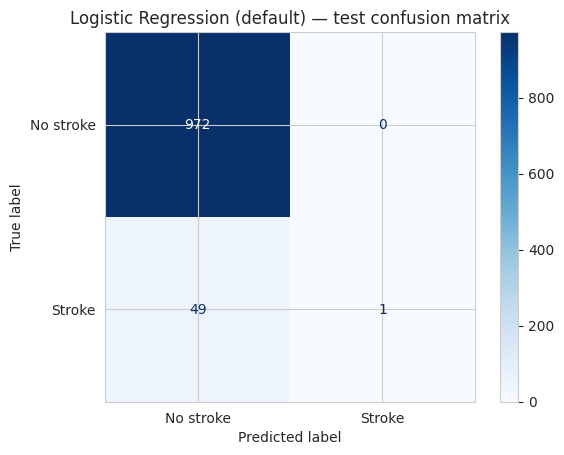

**Your numbers:** baseline accuracy **0.9511** vs Logistic Regression **0.9521**. The model's recall is **0.020**: 
it found **1** of 50 strokes and missed **49**, yet its ROC AUC is 0.839 and PR AUC 0.269 (no-skill PR AUC = 0.049).

In [ ]:
def score_proba(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'ROC AUC': roc_auc_score(y_true, proba), 'PR AUC': average_precision_score(y_true, proba)}

def evaluate(model, Xtr, ytr, Xte, yte):
    # helper from the manual: fit the model and return the six metrics on the test set
    model.fit(Xtr, ytr); return score_proba(yte, model.predict_proba(Xte)[:, 1])

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
m_dummy = score_proba(y_test, dummy.predict_proba(X_test)[:, 1])
lr0 = LogisticRegression(max_iter=1000, random_state=SEED)
m_lr0 = evaluate(lr0, X_train_s, y_train, X_test_s, y_test)
t1 = pd.DataFrame([m_dummy, m_lr0], index=['Majority-class baseline', 'Logistic Regression (default)']); display(t1.round(4))
cm = confusion_matrix(y_test, lr0.predict(X_test_s)); tn, fp, fn, tp = cm.ravel()
ConfusionMatrixDisplay(cm, display_labels=['No stroke', 'Stroke']).plot(cmap='Blues'); plt.title('Logistic Regression (default) — test confusion matrix'); plt.show()
say(f'''**Your numbers:** baseline accuracy **{m_dummy['Accuracy']:.4f}** vs Logistic Regression **{m_lr0['Accuracy']:.4f}**. The model's recall is **{m_lr0['Recall']:.3f}**:
it found **{tp}** of {tp+fn} strokes and missed **{fn}**, yet its ROC AUC is {m_lr0['ROC AUC']:.3f} and PR AUC {m_lr0['PR AUC']:.3f} (no-skill PR AUC = {base_rate:.3f}).''')

### Answers — Part 1
**Baseline vs Logistic Regression.** The "always predict no-stroke" baseline already has **0.9511** accuracy, and the default Logistic Regression has **0.9521** — one patient better. By accuracy the logistic model looks excellent, yet it is **useless as a screening tool**: its recall is **0.02** (it found 1 of 50 strokes and missed 49). Accuracy is dominated by the 95% majority class, so a model can score 95% while finding almost none of the cases we care about.

**False negatives and the right metrics.** In the hospital a false negative is a patient who is going to have a stroke but is told they are fine, so nobody investigates blood pressure, glucose or treatment — the most expensive error (death or permanent disability). The numbers to trust are **recall (sensitivity)**, **precision**, and the threshold-free **ROC AUC and PR AUC**, together with the confusion-matrix counts. Note also that the model's ROC AUC is **0.839** and PR AUC **0.269** (vs a no-skill 0.049): it *does* rank patients sensibly — the problem is the 0.5 cut-off, which Part 3 fixes. (The precision of 1.00 comes from a single flagged patient and means nothing.)

## Part 2 — Underfitting, Overfitting, Bias and Variance

### Task 2.1 — Validation curve

,Train AUC,CV AUC,CV std
max_depth,,,
1,0.7523,0.7317,0.0158
2,0.8283,0.8168,0.0267
3,0.8470,0.8161,0.0288
4,0.8658,0.8180,0.0306
5,0.8900,0.7921,0.0339
6,0.9150,0.7585,0.0487
7,0.9377,0.7385,0.0570
8,0.9573,0.7138,0.0430
9,0.9748,0.6812,0.0296


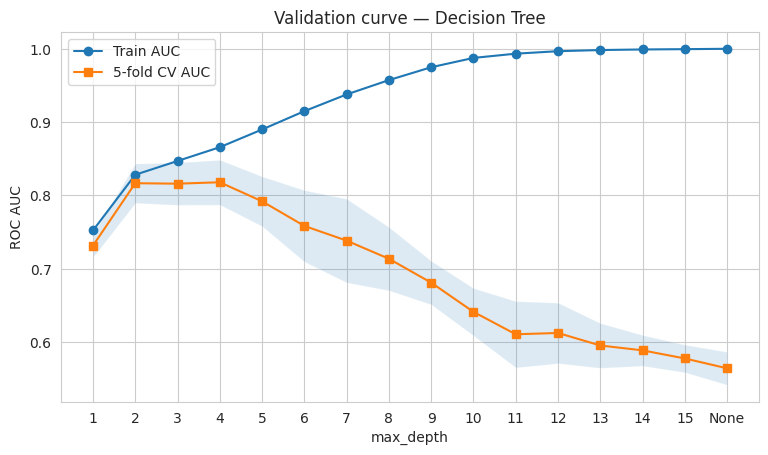

Best depth by CV AUC: 4 | CV AUC = 0.818


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]; rows = []
for d in depths:
    cv = cross_validate(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train, cv=skf, scoring='roc_auc', return_train_score=True)
    rows.append({'max_depth': 'None' if d is None else d, 'Train AUC': cv['train_score'].mean(), 'CV AUC': cv['test_score'].mean(), 'CV std': cv['test_score'].std()})
vc_tab = pd.DataFrame(rows).set_index('max_depth'); display(vc_tab.round(4))
plt.figure(figsize=(9, 4.8)); xs = range(len(vc_tab))
plt.plot(xs, vc_tab['Train AUC'], 'o-', label='Train AUC'); plt.plot(xs, vc_tab['CV AUC'], 's-', label='5-fold CV AUC')
plt.fill_between(xs, vc_tab['CV AUC'] - vc_tab['CV std'], vc_tab['CV AUC'] + vc_tab['CV std'], alpha=.15)
plt.xticks(xs, vc_tab.index); plt.xlabel('max_depth'); plt.ylabel('ROC AUC'); plt.title('Validation curve — Decision Tree'); plt.legend(); plt.show()
best_depth = vc_tab['CV AUC'].idxmax(); print('Best depth by CV AUC:', best_depth, '| CV AUC =', round(vc_tab['CV AUC'].max(), 4))

### Task 2.2 — Learning curves

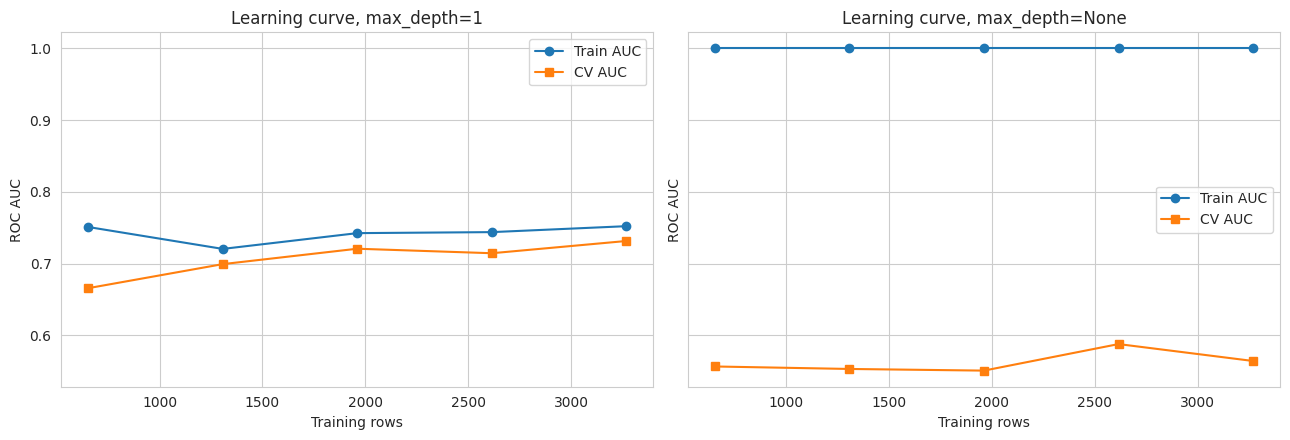

depth 1: train sizes [653, 1307, 1961, 2615, 3269] | train AUC [0.751, 0.721, 0.743, 0.744, 0.752] | CV AUC [0.666, 0.699, 0.721, 0.715, 0.732]
depth None: train sizes [653, 1307, 1961, 2615, 3269] | train AUC [1.0, 1.0, 1.0, 1.0, 1.0] | CV AUC [0.557, 0.553, 0.551, 0.588, 0.564]


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True); lc = {}
for a, d in zip(ax, [1, None]):
    sizes, tr, va = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train, cv=skf, scoring='roc_auc',
                                   train_sizes=np.linspace(0.2, 1.0, 5), shuffle=True, random_state=SEED)
    lc[d] = (sizes, tr.mean(1), va.mean(1))
    a.plot(sizes, tr.mean(1), 'o-', label='Train AUC'); a.plot(sizes, va.mean(1), 's-', label='CV AUC')
    a.set_title(f'Learning curve, max_depth={d}'); a.set_xlabel('Training rows'); a.set_ylabel('ROC AUC'); a.legend()
plt.tight_layout(); plt.show()
for d in lc: print(f'depth {d}: train sizes {lc[d][0].astype(int).tolist()} | train AUC {np.round(lc[d][1],3).tolist()} | CV AUC {np.round(lc[d][2],3).tolist()}')

### Task 2.3 — Measure variance directly

In [ ]:
rng = np.random.default_rng(SEED); B = 40
boot_idx = [rng.choice(len(X_train), len(X_train), replace=True) for _ in range(B)]    # same 40 bootstrap samples for every depth
rows, boot_probs = [], {}
for d in [1, 3, None]:
    P = np.zeros((B, len(X_test))); single = []
    for b, idx in enumerate(boot_idx):
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train.iloc[idx], y_train.iloc[idx])
        P[b] = t.predict_proba(X_test)[:, 1]; single.append(roc_auc_score(y_test, P[b]))
    boot_probs[d] = P
    rows.append({'max_depth': 'None' if d is None else d, 'Mean prediction variance': P.var(axis=0).mean(),
                 'Mean test AUC (single tree)': np.mean(single), 'Std of single-tree AUC': np.std(single), 'AUC of averaged prediction': roc_auc_score(y_test, P.mean(axis=0))})
var_tab = pd.DataFrame(rows).set_index('max_depth'); display(var_tab.round(5))

,Mean prediction variance,Mean test AUC (single tree),Std of single-tree AUC,AUC of averaged prediction
max_depth,,,,
1,0.00068,0.76234,0.01607,0.81317
3,0.00185,0.79300,0.01775,0.83508
None,0.04370,0.55535,0.02307,0.74288


### Interpretation of the tables and plots (Part 2)
*Validation curve:* the train AUC rises steadily from 0.75 (depth 1) to 1.00 (no limit), while the 5-fold CV AUC rises to a peak of **0.818 at depth 4** and then collapses to 0.56. The gap between the curves is the overfitting. *Learning curves:* depth 1 has train and CV curves that meet at a low level (~0.73–0.75); the unlimited tree has train AUC = 1.0 and CV AUC ≈ 0.55–0.59 at every size. *Variance table:* the prediction variance grows 64× from depth 1 to no limit.

### Answers — Part 2
**Validation curve (zones).** *Underfitting (high bias):* depth 1 — train AUC **0.752**, CV AUC **0.732**: both low and close together. *Good zone:* depths 2–4 — e.g. depth 4: train 0.866, CV **0.818** (best); depths 2, 3 and 4 have CV AUCs of 0.817, 0.816 and 0.818, which differ by far less than one CV standard deviation (≈0.03), so they are equivalent. *Overfitting (high variance):* depth 8 — train 0.957 but CV 0.714; no limit — train **1.000** but CV **0.564**. I would choose **depth 3** (simplest model in the plateau, equal to the best within noise, lowest variance of the good depths; depth 4 is the best by the raw number).

**Learning curves.** *High bias:* the train and CV curves are close together and both stay **low** (depth 1: train ≈ 0.72–0.75, CV rises 0.67 → 0.73 and approaches the train curve) — the model is too simple even for the data it has seen. *High variance:* train AUC stays near the maximum (1.0) while CV is far below (0.55–0.59) and the **gap persists** (depth None). **More rows:** will not fix high bias — the depth-1 curves have already converged near the ceiling of what a one-split tree can do. For high variance more data would help in principle, but here CV AUC barely moved from 653 to 3,269 rows (0.557 → 0.564), so we would need far more data than we can get; limiting depth or averaging many trees is a much cheaper cure.

**Variance table.** The mean prediction variance rises from **0.00068** (depth 1) to **0.00185** (depth 3) to **0.0437** (no limit) — the unlimited tree is ~64× less stable than the stump: a slightly different training sample gives very different predictions for the same patient. **Averaging** the 40 trees raises the AUC from 0.762 → **0.813** (depth 1), 0.793 → **0.835** (depth 3) and 0.555 → **0.743** (no limit): the gain is by far the largest (+0.19) for the high-variance tree, because averaging cancels the random part of its errors. But the averaged deep trees (0.743) are still worse than a single depth-3 tree (0.793): averaging removes *variance*, not the *noise memorised* by each tree. This is what **Random Forest** does: it averages many trees grown on bootstrap samples (plus random feature subsets, and here `min_samples_leaf=5` to keep the trees from memorising) — which is why the forest (AUC 0.822 in Part 3) is so much better than one unlimited tree (0.555).

**Bias-variance trade-off in my own words.** Total prediction error = bias² (error from the model being too simple to represent the truth) + variance (error from the model changing when the training data changes) + irreducible noise. Making the model more flexible lowers bias but raises variance, so test error is lowest at an intermediate complexity. *Depth 1* sits at **high bias / low variance** (train 0.75 ≈ CV 0.73, variance 0.0007); *depth 3* is near the **sweet spot** (CV 0.816, variance 0.0019); *depth None* is **low bias / very high variance** (train 1.00, CV 0.56, variance 0.044).

## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare models with curves

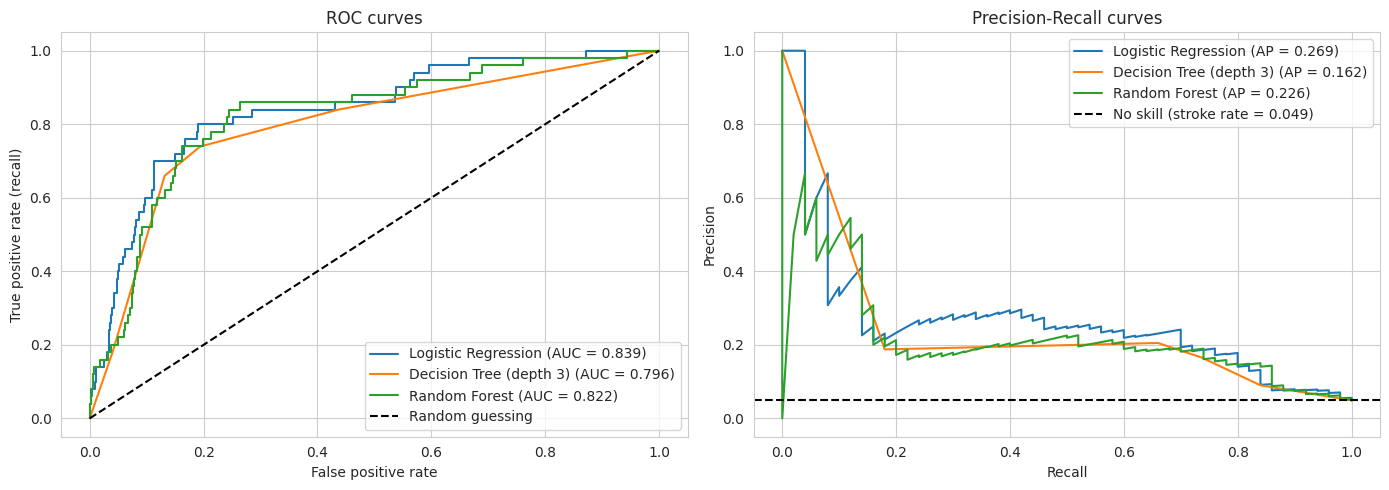

,ROC AUC,PR AUC (AP)
Logistic Regression,0.8394,0.2692
Decision Tree (depth 3),0.7956,0.1621
Random Forest,0.8224,0.2255


In [ ]:
lr = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_s, y_train)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
P3 = {'Logistic Regression': lr.predict_proba(X_test_s)[:, 1], 'Decision Tree (depth 3)': dt3.predict_proba(X_test)[:, 1], 'Random Forest': rf.predict_proba(X_test)[:, 1]}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for n, p in P3.items():
    f, t, _ = roc_curve(y_test, p); ax[0].plot(f, t, label=f'{n} (AUC = {roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f'{n} (AP = {average_precision_score(y_test, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guessing'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate (recall)'); ax[0].set_title('ROC curves'); ax[0].legend()
ax[1].axhline(y_test.mean(), color='k', ls='--', label=f'No skill (stroke rate = {y_test.mean():.3f})'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-Recall curves'); ax[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({n: {'ROC AUC': roc_auc_score(y_test, p), 'PR AUC (AP)': average_precision_score(y_test, p)} for n, p in P3.items()}).T.round(4))

### Task 3.2 — Choose a decision threshold (training data only)

Chosen threshold = 0.0509 | out-of-fold recall = 0.804, precision = 0.136


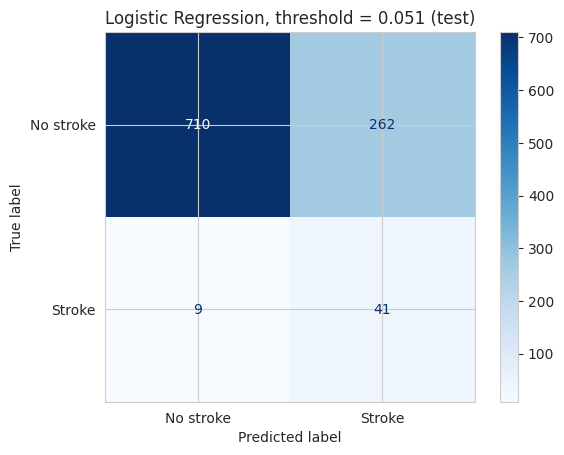

**Your numbers:** at threshold **0.051** (chosen on training data only) the test recall is **0.820** (41 of 50 strokes caught), precision **0.135**. 
**303** of 1022 patients (29.6%) are flagged, of whom **262** are false alarms (**86%** of the flags); **9** strokes are still missed.

In [ ]:
oof = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)), X_train, y_train,
                        cv=skf, method='predict_proba')[:, 1]                      # out-of-fold probabilities, scaler re-fit inside each fold
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof)
THR = float(thr_o[np.argmax(tpr_o >= 0.80)])                                         # highest threshold with out-of-fold recall >= 0.80
oof_pred = (oof >= THR).astype(int)
print(f'Chosen threshold = {THR:.4f} | out-of-fold recall = {recall_score(y_train, oof_pred):.3f}, precision = {precision_score(y_train, oof_pred):.3f}')

p_lr = P3['Logistic Regression']; pred_thr = (p_lr >= THR).astype(int)
m_thr = score_proba(y_test, p_lr, THR); cm_t = confusion_matrix(y_test, pred_thr); tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
ConfusionMatrixDisplay(cm_t, display_labels=['No stroke', 'Stroke']).plot(cmap='Blues'); plt.title(f'Logistic Regression, threshold = {THR:.3f} (test)'); plt.show()
say(f'''**Your numbers:** at threshold **{THR:.3f}** (chosen on training data only) the test recall is **{m_thr['Recall']:.3f}** ({tp_t} of {tp_t+fn_t} strokes caught), precision **{m_thr['Precision']:.3f}**.
**{tp_t+fp_t}** of {len(y_test)} patients ({100*(tp_t+fp_t)/len(y_test):.1f}%) are flagged, of whom **{fp_t}** are false alarms (**{fp_t/(tp_t+fp_t):.0%}** of the flags); **{fn_t}** strokes are still missed.''')

### Interpretation of the curves (Part 3)
On the ROC plot all three models lie above the diagonal, with Logistic Regression on top (AUC **0.839**, vs 0.822 Random Forest and 0.796 depth-3 tree). On the Precision-Recall plot the same order holds (AP **0.269** vs 0.226 and 0.162) but precision falls quickly as recall rises — to about 0.2–0.3 for most of the range and towards the no-skill line (0.049) when recall exceeds ~0.8. Logistic Regression is the best model on both curves, so I use it for the threshold.

### Answers — Part 3
**Both facts can be true.** ROC AUC is the probability that a randomly chosen stroke patient gets a *higher score* than a randomly chosen healthy patient — it only depends on the **ranking**, not on any cut-off. The logistic model ranks well (AUC 0.84), but because only 5% of patients have strokes, its predicted probabilities are mostly small (even high-risk patients are rarely above 0.5), so the default **0.5 threshold** flags only 1 patient and recall is 0.02. The ranking is good; the threshold is in the wrong place. Choosing the threshold from the training data (0.051) catches **41 of 50** strokes (recall **0.82**) on the test set.

**ROC or PR?** The **Precision-Recall** curve is more informative for this data. The ROC curve looks good because the false-positive *rate* divides by 972 healthy patients: 262 false alarms are only a 27% false-positive rate, yet they are 86% of everything flagged. The PR curve shows that burden directly (precision ≈ 0.13 at 80% recall), and the no-skill line at 0.049 shows the baseline to beat: AP 0.269 is about 5.5× no-skill — useful, but far less impressive than "AUC 0.84" sounds.

**The price of higher recall, both sides.** *Acceptable:* a missed stroke can mean death or lifelong disability, while a false alarm usually costs only a follow-up check (blood pressure, glucose, ECG); catching 41 of 50 strokes needs ~7.4 flagged patients per stroke found, and 13.5% precision is 2.8× the 4.9% base rate. *Not acceptable if:* 303 of 1,022 patients (**30%**) are flagged, 86% of them healthy — that is a lot of unnecessary appointments, cost, anxiety and alarm fatigue, and if the follow-up were expensive or invasive the hospital might prefer a lower recall target (e.g. 60–70%) with fewer flags. Since the follow-up here is cheap compared with a stroke, I find the trade acceptable for a *screening* step.

## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the methods (resampling the TRAIN set only)

In [ ]:
MODELS = {'Logistic Regression': (lambda **kw: LogisticRegression(max_iter=1000, random_state=SEED, **kw), 'scaled'),
          'Random Forest':       (lambda **kw: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1, **kw), 'raw')}
METHODS = ['none', "class_weight='balanced'", 'random undersampling', 'random oversampling', 'SMOTE']
def resampler(m):
    return {'random undersampling': RandomUnderSampler(random_state=SEED), 'random oversampling': RandomOverSampler(random_state=SEED), 'SMOTE': SMOTE(random_state=SEED)}.get(m)
rows, res4, probs4 = [], {}, {}
for mname, (make, kind) in MODELS.items():
    Xtr, Xte = (X_train_s, X_test_s) if kind == 'scaled' else (X_train, X_test)
    for meth in METHODS:
        model = make(class_weight='balanced') if meth == "class_weight='balanced'" else make()
        rs = resampler(meth)
        Xf, yf = rs.fit_resample(Xtr, y_train) if rs is not None else (Xtr, y_train)        # test set is never resampled
        model.fit(Xf, yf); p = model.predict_proba(Xte)[:, 1]; s = score_proba(y_test, p)
        res4[(mname, meth)] = s; probs4[(mname, meth)] = p
        rows.append({'Model': mname, 'Method': meth, 'Train rows': len(yf), 'Train strokes': int(yf.sum()), **s})
t4 = pd.DataFrame(rows).set_index(['Model', 'Method']).drop(columns='Accuracy'); display(t4.round(4))

Train rows  Train strokes  Precision  Recall      F1  ROC AUC  PR AUC
Model               Method                                                                                        
Logistic Regression none                           4087            199     1.0000    0.02  0.0392   0.8394  0.2692
                    class_weight='balanced'        4087            199     0.1347    0.80  0.2305   0.8395  0.2595
                    random undersampling            398            199     0.1246    0.82  0.2164   0.8352  0.2338
                    random oversampling            7776           3888     0.1333    0.80  0.2286   0.8385  0.2646
                    SMOTE                          7776           3888     0.1338    0.80  0.2292   0.8406  0.2876
Random Forest       none                           4087            199     0.0000    0.00  0.0000   0.8224  0.2255
                    class_weight='balanced'        4087            199     0.2143    0.30  0.2500   0.8109  0.2088
                    random undersampling            398            199     0.1050    0.84  0.1867   0.8203  0.2030
                    random oversampling            7776           3888     0.1882    0.32  0.2370   0.8111  0.1906
                    SMOTE                          7776           3888     0.5000    0.06  0.1071   0.7977  0.2290

### Task 4.2 — The classic mistake: SMOTE before splitting

In [ ]:
X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_all, y_all)                        # WRONG ORDER: resample everything first ...
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_sm, y_sm, test_size=0.2, stratify=y_sm, random_state=SEED)   # ... then split
rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
m_wrong = evaluate(rf_wrong, Xa_tr, ya_tr, Xa_te, ya_te)
m_right = res4[('Random Forest', 'SMOTE')]
t42 = pd.DataFrame([m_wrong, m_right], index=['WRONG: SMOTE on all data, then split', 'CORRECT: split, then SMOTE on train only']); display(t42.round(4))
print(f'Wrong-order test set: {len(ya_te)} rows, {100*ya_te.mean():.0f}% strokes (of which many are synthetic) | correct test set: {len(y_test)} rows, {100*y_test.mean():.1f}% strokes (all real)')

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
"WRONG: SMOTE on all data, then split",0.9753,0.9925,0.9578,0.9749,0.9953,0.9962
"CORRECT: split, then SMOTE on train only",0.9511,0.5000,0.0600,0.1071,0.7977,0.2290


Wrong-order test set: 1944 rows, 50% strokes (of which many are synthetic) | correct test set: 1022 rows, 4.9% strokes (all real)


### Interpretation of the table (Part 4.1)
For Logistic Regression every rebalancing method gives almost exactly the same row: recall about 0.80–0.82, precision about 0.12–0.13, F1 about 0.22–0.23 and ROC AUC 0.835–0.841. For Random Forest the methods behave very differently from one another (recall 0.00, 0.30, 0.84, 0.32, 0.06) and the AUCs do not improve.

### Answers — Part 4
**Logistic Regression — what changed and what did not.** *Changed:* recall at the 0.5 cut-off jumped from **0.02 to 0.80–0.82** with every method, precision dropped from "1.0" (one patient) to ~0.13, and F1 rose from 0.04 to ~0.23. *Did not change:* the **ROC AUC (0.8394 → 0.835–0.841)** and PR AUC (0.26–0.29), i.e. the *ranking* of patients. Reason: for a linear model, weighting or resampling mostly shifts the intercept (the prior), which slides the decision boundary and so moves where 0.5 falls along the *same* ranking; it adds no new information about who is at risk. This is the same as simply lowering the threshold: the F1 of 0.232 from the Part 3 threshold equals the F1 of balanced weights (0.231), SMOTE (0.229) and oversampling (0.229).

**Random Forest — a different reaction.** Logistic Regression reacted the same way to all four methods; the Random Forest did not. Class weights and random oversampling lifted recall only to 0.30–0.32, **SMOTE barely moved it (0.06)**, while **undersampling lifted it to 0.84** (precision 0.105); and the ROC AUC of the forest *fell* with weights/oversampling/SMOTE (0.822 → 0.811, 0.811, 0.798). Possible reason: a forest is a non-linear, high-variance model. Duplicated or synthetic stroke rows are not just a prior shift — they create new regions and leaves, so the trees memorise copies of the same few real patients (and, with SMOTE, interpolated points that sit between them), which overfits instead of generalising; undersampling instead keeps only real rows and shifts the forest's class prior, which is why it behaves like the logistic model. (SMOTE also interpolates the 0/1 dummy columns into fractional values that never occur in real patients.)

**Wrong order vs correct order.** Wrong order gives accuracy 0.975, recall **0.958**, precision 0.993, ROC AUC **0.995**, PR AUC **0.996**; the correct result is recall **0.06**, precision 0.50, ROC AUC **0.798**, PR AUC **0.229**. The wrong-order numbers are far too good because (1) SMOTE made synthetic strokes by interpolating between real stroke patients *from the whole data set*, so after the split, the synthetic points in the test set have "siblings" built from the same real patients in the training set — information leaks from test to train and the forest is tested on near-copies of what it memorised; (2) the "test set" is no longer a sample of real patients: ~50% of it is strokes, and about 95% of those are synthetic, so precision, PR AUC and accuracy are measured on a completely different, much easier problem (1,944 rows, 50% strokes vs the real 4.9%). The model has learned nothing about unseen real patients, so these numbers cannot be trusted. Resampling is part of *training* and must happen only on the training fold.

**My pick for the hospital.** A **Logistic Regression with a threshold (or `class_weight='balanced'`) learned from the training data**: it gives the same recall/F1 as SMOTE or oversampling (F1 0.23, AUC 0.84) without enlarging the data to 7,776 rows or inventing synthetic patients, is the simplest to explain, and its only cost is the false alarms that every method pays equally. Undersampling throws away 90% of the training rows (398 left) for a slightly lower AUC (0.835) and PR AUC (0.234); SMOTE and oversampling cost more compute and, as Part 5 shows, can hurt when the labels are noisy.

## Part 5 — Noisy Data

In [ ]:
def flip_labels(y, frac, rng):
    y2 = y.to_numpy().copy(); n_flip = int(round(frac * len(y2))); idx = rng.choice(len(y2), n_flip, replace=False)
    y2[idx] = 1 - y2[idx]; return pd.Series(y2, index=y.index)

def auc_four(Xtr, ytr, Xte, Xtr_s, Xte_s):
    # test ROC AUC of the four models (LR uses the scaled copy)
    out = {}
    out['Logistic Regression'] = roc_auc_score(y_test, LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr_s, ytr).predict_proba(Xte_s)[:, 1])
    out['Decision Tree (depth 3)'] = roc_auc_score(y_test, DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(Xtr, ytr).predict_proba(Xte)[:, 1])
    out['Decision Tree (no limit)'] = roc_auc_score(y_test, DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr).predict_proba(Xte)[:, 1])
    out['Random Forest'] = roc_auc_score(y_test, RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(Xtr, ytr).predict_proba(Xte)[:, 1])
    return out

### Task 5.1 — Label noise

,Logistic Regression,Decision Tree (depth 3),Decision Tree (no limit),Random Forest
flip fraction,,,,
0.00,0.8394,0.7956,0.5797,0.8224
0.05,0.8241,0.8014,0.5529,0.8034
0.10,0.8133,0.8029,0.5105,0.7592
0.20,0.7743,0.7260,0.5045,0.6831


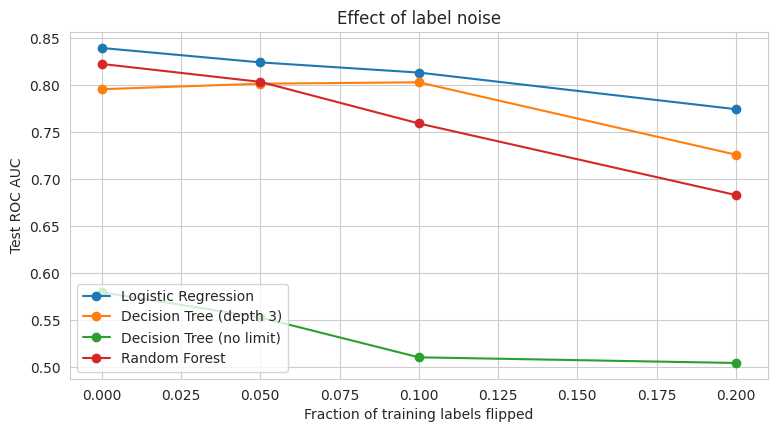

In [ ]:
fracs = [0, 0.05, 0.10, 0.20]; lab_rows = {}
for fr in fracs:
    reps = 1 if fr == 0 else 5; acc = []
    for r in range(reps):
        y_noisy = flip_labels(y_train, fr, np.random.default_rng(SEED + r))
        acc.append(auc_four(X_train, y_noisy, X_test, X_train_s, X_test_s))
    lab_rows[fr] = pd.DataFrame(acc).mean()
label_tab = pd.DataFrame(lab_rows).T.rename_axis('flip fraction'); display(label_tab.round(4))
label_tab.plot(marker='o', figsize=(9, 4.5)); plt.ylabel('Test ROC AUC'); plt.xlabel('Fraction of training labels flipped'); plt.title('Effect of label noise'); plt.legend(loc='lower left'); plt.show()

### Task 5.2 — Feature noise

,Logistic Regression,Decision Tree (depth 3),Decision Tree (no limit),Random Forest
noise level (x std),,,,
0.0,0.8394,0.7956,0.5797,0.8224
0.5,0.8337,0.7995,0.5608,0.8140
1.0,0.8098,0.7610,0.5283,0.7870
2.0,0.7695,0.6942,0.5309,0.7406


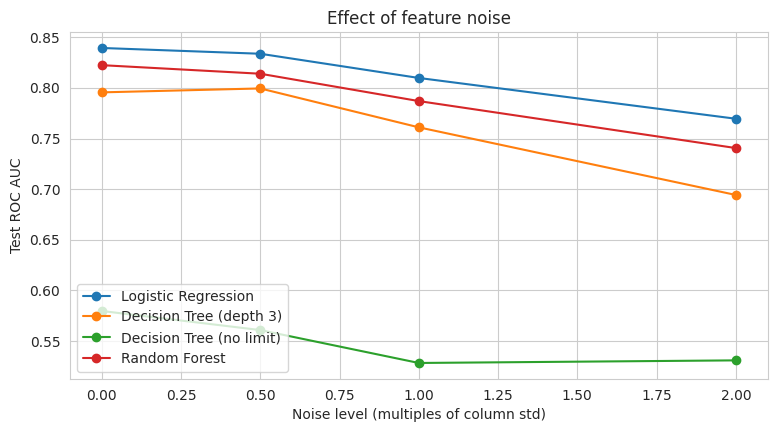

In [ ]:
noisy_cols = ['age', 'avg_glucose_level', 'bmi']; levels = [0, 0.5, 1, 2]; feat_rows = {}; stds = X_train[noisy_cols].std()
for lv in levels:
    reps = 1 if lv == 0 else 5; acc = []
    for r in range(reps):
        g = np.random.default_rng(SEED + r); Xn = X_train.copy()
        for c in noisy_cols: Xn[c] = Xn[c] + g.normal(size=len(Xn)) * stds[c] * lv          # noise on TRAIN only
        sc = StandardScaler().fit(Xn)                                                       # scaler fitted on the noisy train data
        acc.append(auc_four(Xn, y_train, X_test, sc.transform(Xn), sc.transform(X_test)))
    feat_rows[lv] = pd.DataFrame(acc).mean()
feat_tab = pd.DataFrame(feat_rows).T.rename_axis('noise level (x std)'); display(feat_tab.round(4))
feat_tab.plot(marker='o', figsize=(9, 4.5)); plt.ylabel('Test ROC AUC'); plt.xlabel('Noise level (multiples of column std)'); plt.title('Effect of feature noise'); plt.legend(loc='lower left'); plt.show()

### Task 5.3 — SMOTE and noisy labels

In [ ]:
rows = []; check = []
for r in range(3):
    y_noisy = flip_labels(y_train, 0.10, np.random.default_rng(SEED + r))
    true_pos = int(((y_noisy == 1) & (y_train == 1)).sum()); check.append((int(y_noisy.sum()), true_pos))
    for mname, (make, kind) in MODELS.items():
        Xtr, Xte = (X_train_s, X_test_s) if kind == 'scaled' else (X_train, X_test)
        for use_smote in [False, True]:
            Xf, yf = SMOTE(random_state=SEED).fit_resample(Xtr, y_noisy) if use_smote else (Xtr, y_noisy)    # SMOTE applied AFTER the noise
            p = make().fit(Xf, yf).predict_proba(Xte)[:, 1]
            rows.append({'Model': mname, 'SMOTE': 'with SMOTE' if use_smote else 'without', 'ROC AUC': roc_auc_score(y_test, p), 'PR AUC': average_precision_score(y_test, p)})
t53 = pd.DataFrame(rows).groupby(['Model', 'SMOTE']).mean().round(4); display(t53)
print('Noisy training set (3 draws): (labelled stroke, of which truly stroke) =', check)

ROC AUC  PR AUC
Model               SMOTE                      
Logistic Regression with SMOTE   0.8158  0.2259
                    without      0.8140  0.2174
Random Forest       with SMOTE   0.6635  0.1026
                    without      0.7482  0.1543

Noisy training set (3 draws): (labelled stroke, of which truly stroke) = [(572, 181), (556, 173), (564, 177)]


In [ ]:
drops_lab = (label_tab.loc[0] - label_tab.loc[0.20]); drops_feat = (feat_tab.loc[0] - feat_tab.loc[2])
most_l, least_l = drops_lab.idxmax(), drops_lab.idxmin(); most_f, least_f = drops_feat.idxmax(), drops_feat.idxmin()
n_lab, n_true = np.mean([c[0] for c in check]), np.mean([c[1] for c in check])
say(f'''**Label noise 0 → 20%:** AUC falls by {', '.join(f"{k} {v:.3f}" for k, v in drops_lab.items())} → most damaged **{most_l}**, most stable **{least_l}**.
**Feature noise 0 → 2×std:** falls by {', '.join(f"{k} {v:.3f}" for k, v in drops_feat.items())} → most damaged **{most_f}**, most stable **{least_f}**.
**With 10% flipped labels** the training set has on average **{n_lab:.0f}** rows labelled "stroke", of which only **{n_true:.0f}** are real strokes (the other {n_lab-n_true:.0f} are healthy patients whose label was flipped).''')

**Label noise 0 → 20%:** AUC falls by Logistic Regression 0.065, Decision Tree (depth 3) 0.070, Decision Tree (no limit) 0.075, Random Forest 0.139 → most damaged **Random Forest**, most stable **Logistic Regression**. 
**Feature noise 0 → 2×std:** falls by Logistic Regression 0.070, Decision Tree (depth 3) 0.101, Decision Tree (no limit) 0.049, Random Forest 0.082 → most damaged **Decision Tree (depth 3)**, most stable **Decision Tree (no limit)**. 
**With 10% flipped labels** the training set has on average **564** rows labelled "stroke", of which only **177** are real strokes (the other 387 are healthy patients whose label was flipped).

### Interpretation of the noise experiments (Part 5)
*Label noise table/plot:* every model loses AUC as more labels are flipped; Random Forest drops the most (0.822 → 0.683 at 20%), Logistic Regression the least (0.839 → 0.774). The unlimited tree is already near 0.5 (chance) at 0% noise and ends at 0.50 — it cannot fall much further. *Feature noise:* all models lose AUC as noise grows; the depth-3 tree loses the most (0.796 → 0.694 at 2×std), Logistic Regression 0.839 → 0.770, Random Forest 0.822 → 0.741. *SMOTE + noise:* with SMOTE the logistic model is unchanged (0.814 → 0.816) while the forest gets worse (0.748 → 0.664).

### Answers — Part 5
**Most damaged / most stable.** At the highest **label** noise (20%): Random Forest is the most damaged (**−0.139**, to 0.683), then DT-no-limit (−0.075), DT depth 3 (−0.070) and Logistic Regression is the most stable (**−0.065**, still 0.774). At the highest **feature** noise (2×std): the depth-3 tree is the most damaged (**−0.101**), then Random Forest (−0.082), Logistic Regression (−0.070); the unlimited tree "loses" only 0.049, but only because it started at 0.58, barely above chance — among the useful models Logistic Regression is the most stable. Explanation from Part 2: Random Forest and unlimited trees are low-bias / high-variance learners; they have the capacity to fit the training labels exactly, so they *memorise* the wrong labels and the noisy features. Logistic Regression is a high-bias / low-variance model whose few parameters average the noise out (random errors mostly cancel), so it degrades gracefully. A shallow tree is in between, but because it chooses its splits from a few noisy thresholds on age/glucose/bmi, noise in exactly those columns shifts its splits a lot.

**Label noise or feature noise?** In this experiment **label noise hurts more**, and it is much more damaging for the best non-linear model: at the highest levels the average AUC loss is 0.087 for label noise (20% flipped) vs 0.076 for feature noise (2×std), and for Random Forest it is 0.139 vs 0.082. Reason: with only 5% strokes, flipping 10% of labels at random turns about 387 healthy patients into "strokes" while turning only ~22 real strokes into "no stroke" — the training set then has **~564 labelled strokes of which only ~177 (31%) are real**, so the positive class is mostly noise. Feature noise leaves every label correct and only blurs the inputs, so the signal is still there on average.

**SMOTE with noisy labels.** For Logistic Regression SMOTE did almost nothing (ROC AUC 0.8140 → 0.8158, PR AUC 0.217 → 0.226), as in Part 4. For Random Forest it made things **clearly worse** (ROC AUC 0.748 → **0.664**, PR AUC 0.154 → **0.103**). SMOTE creates new "stroke" rows by interpolating between existing stroke-labelled neighbours; when most of those labelled strokes are really healthy patients with flipped labels, SMOTE **manufactures thousands of synthetic wrong-label points** inside the healthy region and, since it also balances the data to 50/50, the noisy class gets as much weight as the real majority. A flexible model like Random Forest then fits that mass of noise. SMOTE assumes that the minority labels are correct — noisy labels break that assumption and SMOTE amplifies the damage.

## Part 6 — Final Decision and Conclusion

In [ ]:
def row(p, thr):
    s = score_proba(y_test, p, thr); pr = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_test, pr).ravel()
    return {'Threshold': thr, 'Precision': s['Precision'], 'Recall': s['Recall'], 'F1': s['F1'], 'Patients flagged': tp + fp, 'False alarms (FP)': fp, 'Missed strokes (FN)': fn, 'Caught strokes (TP)': tp}
final = pd.DataFrame([row(p_lr, 0.5), row(p_lr, THR)], index=['Logistic Regression @ default 0.5', f'Logistic Regression @ chosen {THR:.3f}'])
display(final.round(4))
f0, f1_ = final.iloc[0], final.iloc[1]

,Threshold,Precision,Recall,F1,Patients flagged,False alarms (FP),Missed strokes (FN),Caught strokes (TP)
Logistic Regression @ default 0.5,0.5000,1.0000,0.02,0.0392,1,0,49,1
Logistic Regression @ chosen 0.051,0.0509,0.1353,0.82,0.2323,303,262,9,41


### Interpretation of the final table (Part 6)
At the default threshold the model flags 1 patient and misses 49 of 50 strokes (recall 0.02). With the threshold learned from out-of-fold training predictions (0.051) it catches 41 of 50 strokes (recall 0.82, F1 rises from 0.04 to 0.23), missing only 9, at the cost of 303 flagged patients of whom 262 are false alarms. Nothing about the model changed — only where the cut-off is placed on its probability ranking.

In [ ]:
say(f'''### Executive Summary
For the hospital's stroke screening I recommend **Logistic Regression on standardised features with a decision threshold of {THR:.3f}**, chosen from out-of-fold training predictions so that at least 80% of strokes are caught.
On the held-out test set this catches **{int(f1_['Caught strokes (TP)'])} of {int(f1_['Caught strokes (TP)']+f1_['Missed strokes (FN)'])} strokes (recall {f1_['Recall']:.2f})** with precision **{f1_['Precision']:.2f}**, versus recall {f0['Recall']:.2f} at the default 0.5 threshold.
The price is **{int(f1_['False alarms (FP)'])} false alarms** — {int(f1_['Patients flagged'])} patients ({100*f1_['Patients flagged']/len(y_test):.0f}% of those screened) are flagged for follow-up, and about {f1_['False alarms (FP)']/f1_['Patients flagged']:.0%} of the flags are healthy patients.
It also has the best or near-best ROC AUC ({m_lr0['ROC AUC']:.2f}) and PR AUC ({m_lr0['PR AUC']:.2f}, versus a no-skill {base_rate:.3f}) among the models tested, and needs no resampling.
Leakage was avoided by splitting first (stratified), learning the median, scaler, resampling and threshold from training data only, using a pipeline inside cross-validation, and resampling only the training set.
**Limitations:** the test set has only {int(y_test.sum())} stroke patients, so recall has a wide uncertainty (±{100*1.96*np.sqrt(f1_['Recall']*(1-f1_['Recall'])/y_test.sum()):.0f} points, 95%), the threshold depends on the 80% target and on one cross-validation split, and the model uses only routine variables, so it is a screening aid, not a diagnosis.''')

### Executive Summary
For the hospital's stroke screening I recommend **Logistic Regression on standardised features with a decision threshold of 0.051**, chosen from out-of-fold training predictions so that at least 80% of strokes are caught. 
On the held-out test set this catches **41 of 50 strokes (recall 0.82)** with precision **0.14**, versus recall 0.02 at the default 0.5 threshold. 
The price is **262 false alarms** — 303 patients (30% of those screened) are flagged for follow-up, and about 86% of the flags are healthy patients. 
It also has the best or near-best ROC AUC (0.84) and PR AUC (0.27, versus a no-skill 0.049) among the models tested, and needs no resampling. 
Leakage was avoided by splitting first (stratified), learning the median, scaler, resampling and threshold from training data only, using a pipeline inside cross-validation, and resampling only the training set. 
**Limitations:** the test set has only 50 stroke patients, so recall has a wide uncertainty (±11 points, 95%), the threshold depends on the 80% target and on one cross-validation split, and the model uses only routine variables, so it is a screening aid, not a diagnosis.

### Final Reflection
**(a) Most surprising result:** *(write your own — candidates from this lab: how high the accuracy of a model that finds no strokes is; how large the gap between ROC AUC and recall at 0.5 is; that the resampling methods barely changed Logistic Regression's AUC; how badly the wrong-order SMOTE looks; or how few real strokes remain among the "stroke" labels after flipping 10% of the labels.)*

**(b) With one more hour:** repeated stratified cross-validation (to put error bars on recall and AUC with only 50 test strokes); `SMOTENC`/`BorderlineSMOTE` that handle binary/categorical columns properly; calibrating the probabilities and choosing the threshold from an explicit cost ratio (missed stroke vs false alarm); gradient boosting with `scale_pos_weight`; and a fairness check across gender and age groups.